c:\Users\minh2\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LR AUC: 0.7060225428768454
RF AUC: 0.7346843119013047


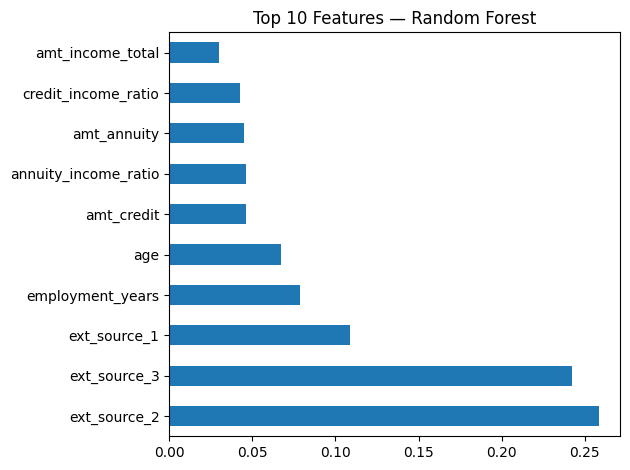

In [1]:
# notebooks/03_ml_baseline.ipynb
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

df = pd.read_csv("../data/processed/application_clean.csv")

# Features
feature_cols = [
    "amt_income_total", "amt_credit", "amt_annuity",
    "age", "employment_years", "credit_income_ratio",
    "annuity_income_ratio", "ext_source_1", "ext_source_2", "ext_source_3",
    "amt_req_credit_bureau_year", "cnt_children", "cnt_fam_members",
]
X = df[feature_cols].fillna(df[feature_cols].median())
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Baseline
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
print("LR AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]))

# Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("RF AUC:", roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1]))

# Feature importance
import matplotlib.pyplot as plt
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
importance.head(10).plot(kind="barh")
plt.title("Top 10 Features — Random Forest")
plt.tight_layout()
plt.savefig("../dashboard/fig_ml_importance.png", dpi=150)